In [7]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [8]:
df = pd.read_csv('/content/diabetes.csv')

In [9]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [10]:
from sklearn.preprocessing import LabelEncoder

le = {}
df_enc = df.copy()
for col in df.columns:
  le[col] = LabelEncoder()
  df_enc[col] = le[col].fit_transform(df[col])

In [11]:
df_enc

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,86,22,28,0,123,350,29,1
1,1,23,19,22,0,62,196,10,0
2,8,121,17,0,0,30,368,11,1
3,1,27,19,16,62,77,53,0,0
4,0,75,4,28,102,209,514,12,1
...,...,...,...,...,...,...,...,...,...
763,10,39,25,41,108,118,55,42,0
764,2,60,21,20,0,155,187,6,0
765,5,59,22,16,71,58,115,9,0
766,1,64,14,0,0,95,195,26,1


In [14]:
x = df_enc[['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']]
y = df_enc['Outcome']

In [15]:
x

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,86,22,28,0,123,350,29
1,1,23,19,22,0,62,196,10
2,8,121,17,0,0,30,368,11
3,1,27,19,16,62,77,53,0
4,0,75,4,28,102,209,514,12
...,...,...,...,...,...,...,...,...
763,10,39,25,41,108,118,55,42
764,2,60,21,20,0,155,187,6
765,5,59,22,16,71,58,115,9
766,1,64,14,0,0,95,195,26


In [16]:
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [17]:
model = CategoricalNB()
model.fit(x, y)

CategoricalNB()

In [18]:
test = [[6,86,22,28,0,123,350,29,1]]

In [19]:
test

[[6, 86, 22, 28, 0, 123, 350, 29, 1]]

In [28]:
print("\n---prediction-----------------------------------")
for t in test:
    row_df = pd.DataFrame([[t[0], t[1], t[2], t[3], t[4], t[5], t[6], t[7]]], columns=x.columns)

    pred = le['Outcome'].inverse_transform(model.predict(row_df))[0]
    prob = model.predict_proba(row_df)[0]

    orig_preg = le['Pregnancies'].inverse_transform([t[0]])[0]
    orig_gluc = le['Glucose'].inverse_transform([t[1]])[0]
    orig_bp = le['BloodPressure'].inverse_transform([t[2]])[0]
    orig_skin = le['SkinThickness'].inverse_transform([t[3]])[0]

    print(f"input : Pregnancies = {orig_preg}, Glucose = {orig_gluc}, BloodPressure = {orig_bp}, SkinThickness = {orig_skin}")
    print(f"output : Outcome = {pred}")
    print(f"p(No) = {prob[0]:.4f}")
    print(f"p(Yes) = {prob[1]:.4f}")


---prediction-----------------------------------
input : Pregnancies = 6, Glucose = 148, BloodPressure = 72, SkinThickness = 35
output : Outcome = 1
p(No) = 0.0380
p(Yes) = 0.9620


In [29]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


Training Accuracy: 92.84%


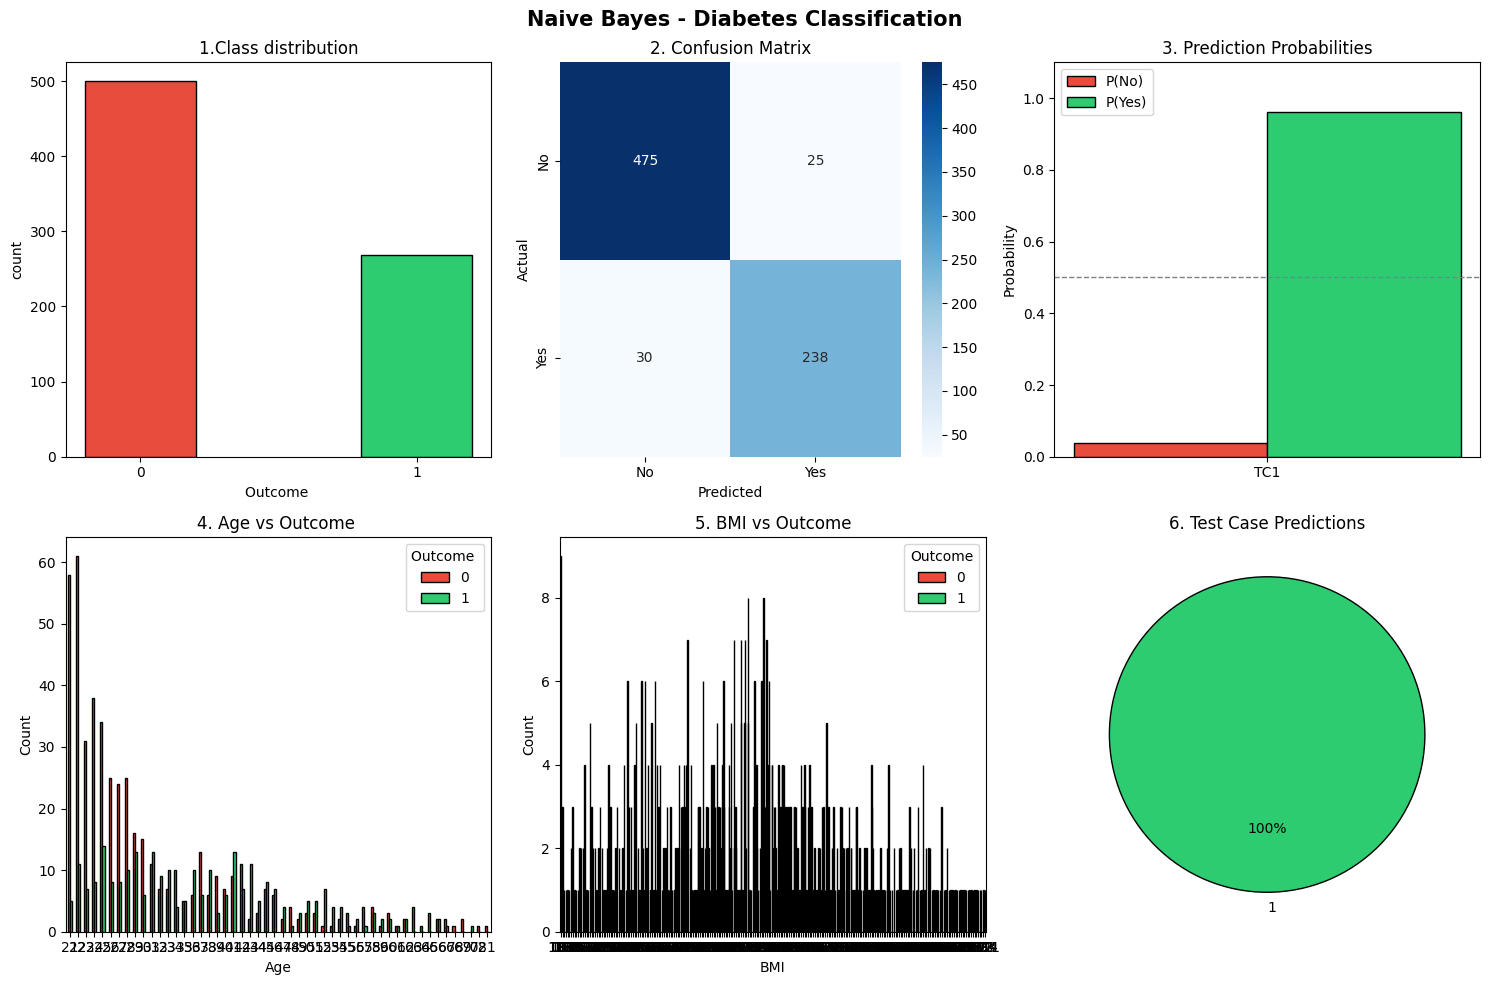

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Calculate predictions for test cases to fix NameError
test_df = pd.DataFrame([t[:8] for t in test], columns=x.columns)
test_predictions = model.predict(test_df)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle("Naive Bayes - Diabetes Classification", fontsize=15, fontweight='bold')

# 1. Class Distribution
counts = df['Outcome'].value_counts()
axes[0, 0].bar(counts.index.astype(str), counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.4)
axes[0, 0].set_title("1.Class distribution")
axes[0, 0].set_xlabel("Outcome ")
axes[0, 0].set_ylabel("count")

# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'],
            yticklabels=['No', 'Yes'], ax=axes[0, 1])
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# 3. Prediction Probabilities (Grouped Bar)
test_cases = test
probs_no = [prob[0]]
probs_yes = [prob[1]]

tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_indices = np.arange(len(tc_labels))
w = 0.3

axes[0, 2].bar(x_indices - w/2, probs_no, w, label='P(No)',
              color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_indices + w/2, probs_yes, w, label='P(Yes)',
              color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_xticks(x_indices)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. Age vs Outcome
age_counts = df.groupby(['Age', 'Outcome']).size().unstack(fill_value=0)
age_counts.plot(
    kind='bar',
    ax=axes[1, 0],
    color=['#e74c3c', '#2ecc71'],
    edgecolor='black',
    rot=0
)
axes[1, 0].set_title("4. Age vs Outcome ")
axes[1, 0].set_xlabel("Age")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title="Outcome ")

# 5. BMI vs Outcome
inc_counts = df.groupby(['BMI', 'Outcome']).size().unstack(fill_value=0)
inc_counts.plot(
    kind='bar',
    ax=axes[1, 1],
    color=['#e74c3c', '#2ecc71'],
    edgecolor='black',
    rot=0
)
axes[1, 1].set_title("5. BMI vs Outcome")
axes[1, 1].set_xlabel("BMI")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend(title="Outcome")

# 6. Pie Chart - Final Predictions
decoded_predictions = le['Outcome'].inverse_transform(test_predictions)
pred_counts = pd.Series(decoded_predictions).value_counts()
colors_pie = ['#2ecc71' if str(i) == '1' else '#e74c3c' for i in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, autopct='%1.0f%%',
              colors=colors_pie, startangle=90,
              wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title('6. Test Case Predictions')
plt.tight_layout()
plt.show()